# 📘 Notebook: Chapter 3 - Tools, Platforms & Ecosystems

This notebook serves as a practical laboratory accompanying Chapter 3 **“Tools, Platforms & Ecosystems.”**  
While the chapter surveys the major frameworks, APIs, and platforms used in current prompt engineering, this notebook focuses on hands-on experimentation. Here, you will work directly with prompt templates, model calls, evaluation loops, and basic metrics, mirroring the workflows used across tools like OpenAI’s APIs, Hugging Face Transformers, LangChain, LlamaIndex, and PromptLayer.

The goal is to provide a reproducible environment where you can iteratively design, test, and compare prompts in a controlled setting. Although the examples use a simple local notebook structure, the same workflow generalizes to the broader tooling ecosystems introduced in the chapter.

---

## Prompt Engineering Experiment Notebook

This notebook is a small laboratory for experimenting with prompt variations
against a set of test inputs. It demonstrates a minimal but extensible workflow
for evaluating prompts, similar to what you might build using LangChain,
PromptLayer, or custom evaluation pipelines.

### Workflow Overview

1. **Setup**  
   - Load dependencies  
   - Configure model and environment  
   - Define a helper to call your LLM API  

2. **Prompt Variations**  
   - Define multiple prompt templates as Python strings  
   - Organize them in a dictionary for easy comparison  

3. **Evaluation Loops**  
   - Run each prompt against a suite of test inputs  
   - Capture responses and metadata in a pandas DataFrame  

4. **Visualization of Metrics**  
   - Compute simple metrics (e.g., response length, latency)  
   - Plot and tabulate results to compare prompt performance  

Replace the `call_model` stub with your actual LLM API integration  
(e.g., OpenAI, Anthropic, Google, or a self-hosted open-source model).

---

By the end of this notebook, you will understand how notebook-based workflows
support rapid prototyping, structured evaluation, and transparent experimentation,
the foundation shared by many of the tools and ecosystems introduced in Chapter 3.


## 1. Setup

In this section we:

- Import Python dependencies
- Configure high-level experiment settings
- Define a reusable `call_model` helper function

> **Note:** `call_model` is currently a stub that just returns a fake response
> so the notebook runs without any external API keys. Replace it with your
> real model call when you’re ready.


In [2]:
from dataclasses import dataclass
from typing import Dict, List, Any
import time

import pandas as pd
import matplotlib.pyplot as plt

# Make pandas tables easier to read inside the notebook
pd.set_option("display.max_colwidth", 200)

# Global configuration (adapt as needed)
MODEL_NAME = "your-model-name-here"
EXPERIMENT_NAME = "prompt-variant-demo"


@dataclass
class PromptVariant:
    """Container describing a prompt variant."""
    name: str
    description: str
    template: str  # A Python format string, expects {input} placeholder.


def call_model(prompt_template: str, input_text: str, model: str = MODEL_NAME, **kwargs) -> str:
    """
    Call your LLM provider here.

    Parameters
    ----------
    prompt_template : str
        The prompt template, typically including `{input}`.
    input_text : str
        The specific input/example to test.
    model : str
        The model identifier.
    kwargs : dict
        Extra parameters (temperature, max_tokens, etc.)

    Returns
    -------
    str
        The model's generated text.
    """
    full_prompt = prompt_template.format(input=input_text)

    # ---------------------------------------------------------------------
    # TODO: Replace this stub with a real API call.
    #
    # Example (pseudo-code):
    #
    #   from openai import OpenAI
    #   client = OpenAI()
    #   response = client.chat.completions.create(
    #       model=model,
    #       messages=[{"role": "user", "content": full_prompt}],
    #       **kwargs,
    #   )
    #   return response.choices[0].message.content
    # ---------------------------------------------------------------------

    # Fake response so the notebook runs offline:
    return f"[FAKE RESPONSE from {model}] Prompt starts with: {full_prompt[:120]!r} ..."


## 2. Define Prompt Variations & Test Inputs

Here we define:

- A small set of **prompt variants** we want to compare
- A small **test set** of inputs

Each prompt template here uses `{input}` which will be filled at runtime.


In [4]:
prompt_variants: Dict[str, PromptVariant] = {
    "baseline": PromptVariant(
        name="baseline",
        description="Simple instruction-only prompt.",
        template=(
            "You are a helpful assistant.\n\n"
            "Task:\n"
            "{input}\n\n"
            "Please provide a concise, clear answer."
        ),
    ),
    "structured": PromptVariant(
        name="structured",
        description="Prompt with explicit sections and a requested output format.",
        template=(
            "You are a precise AI assistant. Follow the structure exactly.\n\n"
            "INSTRUCTIONS:\n"
            "1. Read the task.\n"
            "2. Think step-by-step.\n"
            "3. Respond using the requested format.\n\n"
            "TASK:\n"
            "{input}\n\n"
            "OUTPUT FORMAT:\n"
            "- Summary: <1-2 sentence summary>\n"
            "- Steps: <numbered steps>\n"
            "- Caveats: <short list of caveats, if any>"
        ),
    ),
    "few_shot": PromptVariant(
        name="few_shot",
        description="Prompt with a couple of demonstrations (few-shot).",
        template=(
            "You are an assistant that rewrites text to be clearer and more professional.\n\n"
            "Example 1\n"
            "Input: \"i wanna know how to use this api, it's kinda confusing\"\n"
            "Output: \"I would like to understand how to use this API; its documentation is a bit confusing.\"\n\n"
            "Example 2\n"
            "Input: \"this report is kinda messy, can you fix it up?\"\n"
            "Output: \"This report is somewhat disorganized. Could you help restructure and refine it?\"\n\n"
            "Now rewrite the following input in a similar style:\n\n"
            "Input: \"{input}\"\n"
            "Output:"
        ),
    ),
}

# A tiny test set of inputs (in practice you’d use many more)
test_inputs: List[str] = [
    "Explain the difference between supervised and unsupervised learning.",
    "Rewrite this more professionally: \"our deployment pipeline keeps randomly breaking\"",
    "Give me three bullet points about why version control is important.",
]


## 3. Evaluation Loop

We’ll now:

- Iterate over each prompt variant
- For each variant, iterate over each test input
- Call the model and measure a few basic metrics
- Accumulate everything in a pandas `DataFrame`

You can later extend this with:
- Accuracy/score comparison against ground-truth labels
- Automatic checks for formatting, citations, etc.


In [5]:
def run_experiments(
    prompt_variants: Dict[str, PromptVariant],
    test_inputs: List[str],
    model: str = MODEL_NAME,
    **generation_kwargs: Any,
) -> pd.DataFrame:
    """
    Run each prompt variant against each input and collect results.

    Returns a DataFrame with columns like:
    - variant_name
    - input_text
    - response
    - latency_sec
    - experiment_name
    """
    rows = []

    for variant_key, variant in prompt_variants.items():
        for input_idx, input_text in enumerate(test_inputs):
            start = time.time()
            response = call_model(
                prompt_template=variant.template,
                input_text=input_text,
                model=model,
                **generation_kwargs,
            )
            latency = time.time() - start

            rows.append(
                {
                    "experiment_name": EXPERIMENT_NAME,
                    "variant_name": variant.name,
                    "variant_description": variant.description,
                    "input_id": input_idx,
                    "input_text": input_text,
                    "response": response,
                    "latency_sec": latency,
                    "model_name": model,
                }
            )

    df = pd.DataFrame(rows)
    return df


results_df = run_experiments(prompt_variants, test_inputs, temperature=0.3)

results_df.head()


,experiment_name,variant_name,variant_description,input_id,input_text,response,latency_sec,model_name
0,prompt-variant-demo,baseline,Simple instruction-only prompt.,0,Explain the difference between supervised and unsupervised learning.,[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a helpful assistant.\n\nTask:\nExplain the difference between supervised and unsupervised learning.\n\nPlease provide' ...,0.000016,your-model-name-here
1,prompt-variant-demo,baseline,Simple instruction-only prompt.,1,"Rewrite this more professionally: ""our deployment pipeline keeps randomly breaking""","[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a helpful assistant.\n\nTask:\nRewrite this more professionally: ""our deployment pipeline keeps randomly breaking""\n' ...",0.000022,your-model-name-here
2,prompt-variant-demo,baseline,Simple instruction-only prompt.,2,Give me three bullet points about why version control is important.,[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a helpful assistant.\n\nTask:\nGive me three bullet points about why version control is important.\n\nPlease provide ' ...,0.000005,your-model-name-here
3,prompt-variant-demo,structured,Prompt with explicit sections and a requested output format.,0,Explain the difference between supervised and unsupervised learning.,[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a precise AI assistant. Follow the structure exactly.\n\nINSTRUCTIONS:\n1. Read the task.\n2. Think step-by-step.\n3.' ...,0.000007,your-model-name-here
4,prompt-variant-demo,structured,Prompt with explicit sections and a requested output format.,1,"Rewrite this more professionally: ""our deployment pipeline keeps randomly breaking""",[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a precise AI assistant. Follow the structure exactly.\n\nINSTRUCTIONS:\n1. Read the task.\n2. Think step-by-step.\n3.' ...,0.000005,your-model-name-here


### Inspect Raw Results

It’s often useful to inspect a subset of rows for qualitative analysis:

- How does each prompt **feel**?
- Does it follow the instructions?
- Are there obvious failure modes?


In [6]:
# Show one row per variant for a particular input, e.g. input_id == 0
input_id_to_inspect = 0

results_df.query("input_id == @input_id_to_inspect")[
    ["variant_name", "input_text", "response"]
]


,variant_name,input_text,response
0,baseline,Explain the difference between supervised and unsupervised learning.,[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a helpful assistant.\n\nTask:\nExplain the difference between supervised and unsupervised learning.\n\nPlease provide' ...
3,structured,Explain the difference between supervised and unsupervised learning.,[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are a precise AI assistant. Follow the structure exactly.\n\nINSTRUCTIONS:\n1. Read the task.\n2. Think step-by-step.\n3.' ...
6,few_shot,Explain the difference between supervised and unsupervised learning.,"[FAKE RESPONSE from your-model-name-here] Prompt starts with: 'You are an assistant that rewrites text to be clearer and more professional.\n\nExample 1\nInput: ""i wanna know how to use ' ..."


## 4. Simple Metrics & Visualizations

In a real evaluation, you would compute task-specific metrics:
- **Classification:** accuracy, F1 score, etc.
- **Generation:** BLEU, ROUGE, or custom heuristics
- **Formatting:** pass/fail indicators for JSON validity, etc.

For this example, we’ll compute a couple of simple, generic metrics:

- **Response length** (character count)
- **Latency** (time to get a response; here mostly dummy)


In [7]:
# Basic metrics
results_df["response_length"] = results_df["response"].str.len()

results_df[["variant_name", "input_id", "response_length", "latency_sec"]]


,variant_name,input_id,response_length,latency_sec
0,baseline,0,193,0.000016
1,baseline,1,192,0.000022
2,baseline,2,193,0.000005
3,structured,0,193,0.000007
4,structured,1,193,0.000005
5,structured,2,193,0.000005
6,few_shot,0,191,0.000007
7,few_shot,1,191,0.000006
8,few_shot,2,191,0.000006


### Plot: Response Length by Prompt Variant


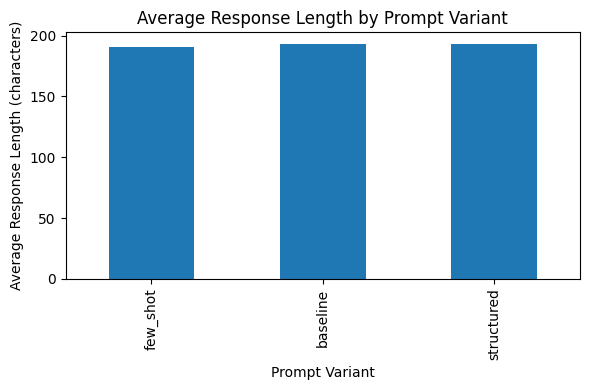

In [8]:
plt.figure(figsize=(6, 4))

(
    results_df.groupby("variant_name")["response_length"]
    .mean()
    .sort_values()
    .plot(kind="bar")
)

plt.title("Average Response Length by Prompt Variant")
plt.xlabel("Prompt Variant")
plt.ylabel("Average Response Length (characters)")
plt.tight_layout()
plt.show()


### Plot: Latency by Prompt Variant

In a real setting, this can help you detect:
- Slow prompts (e.g., very long instructions)
- Backend or model issues


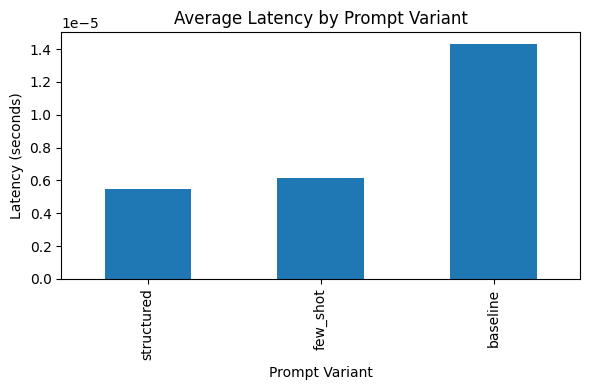

In [9]:
plt.figure(figsize=(6, 4))

(
    results_df.groupby("variant_name")["latency_sec"]
    .mean()
    .sort_values()
    .plot(kind="bar")
)

plt.title("Average Latency by Prompt Variant")
plt.xlabel("Prompt Variant")
plt.ylabel("Latency (seconds)")
plt.tight_layout()
plt.show()


## 5. Next Steps

Some ideas to extend this notebook:

- **Add Ground Truth & Scores**  
  Include a `gold_label` or `expected_output` for each input and compute
  task-specific metrics automatically.

- **Structured Output Checks**  
  Write validators that:
  - Check whether JSON is parseable
  - Verify required fields are present
  - Enforce citation or formatting rules

- **More Prompts & Inputs**  
  Scale up both the number of prompt variants and test examples. Use CSV/JSON
  files to manage larger datasets.

- **Logging & Versioning**  
  Save `results_df` to disk (e.g., as CSV or Parquet) and commit notebooks
  to version control so you can track how prompts evolved over time.

